# Kazakh Profanity Detection — fine-tuning XLM-RoBERTa (Colab)

This notebook runs the whole project in a **fresh Google Colab runtime**:
data preparation → ablation (raw / normalized / normalized + augmentation) → training → one evaluation on the test set →
predictions on your own text → saving the model.

**Before you start:** `Runtime → Change runtime type → T4 GPU`. Total time ≈ 40 minutes (three training runs).

If you only want to **use the trained model** (no training), skip to section 7.

In [1]:
!nvidia-smi -L   # should show a GPU (e.g. Tesla T4)

GPU 0: Tesla T4 (UUID: GPU-d5b13f69-d714-dc8b-8b02-8bd06e915ef3)


## 1. Get the code and install packages

In [2]:
# The GitHub repository must be PUBLIC (or upload the project zip to Colab and unzip it instead of cloning).
REPO_URL = "https://github.com/noorion21/kazakh-profanity-detection.git"  # <- change
!git clone -q $REPO_URL
%cd kazakh-profanity-detection
!pip install -q -r requirements.txt

/content/kazakh-profanity-detection


## 2. Prepare the dataset
The labeled splits are already in `data/processed/`. Running this cell rebuilds them from the raw
KazSAnDRA files + my manual labels + the classmate's labels (seed 42) and produces **identical** files.

In [3]:
!python src/prepare_data.py
import json, pandas as pd
pd.set_option("display.max_colwidth", 120)
info = json.load(open("data/processed/split_info.json"))
pd.DataFrame({k: {m: v[m] for m in ["total", "profane_1", "clean_0", "synthetic"]} for k, v in info["splits"].items()}).T

loaded 167961 KazSAnDRA reviews
excluded (ambiguous): 114
after removing exact duplicates: 162758 (profane: 4115)
train:  9382 rows | profane 2881 | clean  6501
val  :  2010 rows | profane  617 | clean  1393
test :  2009 rows | profane  617 | clean  1392
augmented (train only, synthetic): 1200 rows
agreement with classmate: {'n_both_labeled': 2870, 'percent_agreement': 0.9875, 'cohen_kappa': 0.9749, 'table': {'peer0_me1': 24, 'peer1_me1': 1437, 'peer0_me0': 1397, 'peer1_me0': 12}}
saved to /content/kazakh-profanity-detection/data/processed


,total,profane_1,clean_0,synthetic
train,9382,2881,6501,0
val,2010,617,1393,0
test,2009,617,1392,0


In [4]:
train = pd.read_csv("data/processed/train.csv", keep_default_na=False)
print(train[train.label == 1].profanity_type.value_counts(), "\n")
train.groupby("label").sample(6, random_state=1)[["text", "label", "profanity_type", "script", "source"]]

profanity_type
insult_only        992
kazakh_obscene     932
russian_obscene    633
mixed_obscene      232
other               53
masked              39
Name: count, dtype: int64 



,text,label,profanity_type,script,source
5392,Менде карпаркин облоблениа Жазылмайтур,0,none,cyrillic_no_kazakh_letters,neg_sentiment
8636,"Баланың денесіне әсері жоқ, сіңіруі де орынша.Бір-екі рет сыртқа шығып кетуі болды, мүмкін дұрыс кигізбеген себебіне...",0,none,cyrillic_with_kazakh_letters,lookalike
4961,"Кіре беріс жол және базардың ішіндегі жол өте тар, шұңқыр-шұңқыр. Машина қоятын орын аз.",0,none,cyrillic_with_kazakh_letters,random
2161,қалай ойнайт как играйт,0,none,cyrillic_with_kazakh_letters,neg_sentiment
5377,Күшті майынкрафт 😍😍😍😍,0,none,cyrillic_with_kazakh_letters,random
1518,"Қандай керемет, тариф біткен де гб жетпи минут артық қалаушы еді. Енді тек минуттарды көтеріп жібермесе болды осы 10...",0,none,cyrillic_with_kazakh_letters,lookalike
1583,Қотақ қотақ,1,kazakh_obscene,cyrillic_with_kazakh_letters,profane_obscene
5562,"толық боқтық, кіріңіз, бірден жарнама шығады.",1,kazakh_obscene,cyrillic_with_kazakh_letters,profane_obscene
3291,ойын малски.Ол ойнда бар жер боладыда бірақ бір ғана жер ашық болады қалаған жерінің бәрі жабық ойын өтірік😒🤧😡😡😡😡😡😡😡...,1,insult_only,cyrillic_with_kazakh_letters,profane_insult
1384,Тартылмайды малдар 👎👎,1,insult_only,cyrillic_no_kazakh_letters,profane_insult


### Text normalization (what the model actually sees)
Latin → Kazakh Cyrillic, Latin look-alike letters fixed, long repeats shortened. Kazakh letters are kept.

In [5]:
import sys; sys.path.insert(0, "src")
from normalize import normalize_text
for t in ["Qotaqbas oyin", "kotak", "shesheńdi mynaý", "Mal eken", "бляяяяя", "Free Fire керемет"]:
    print(f"{t:25} -> {normalize_text(t)}")

Qotaqbas oyin             -> Қотақбас ойин
kotak                     -> котак
shesheńdi mynaý           -> шешеңди мынау
Mal eken                  -> Мал екен
бляяяяя                   -> бляя
Free Fire керемет         -> Фрее Фире керемет


## 3. Training + ablation (with / without each preprocessing step)
Settings are in `config.json` (lr 2e-5, batch 16, 4 epochs, max 128 tokens, seed 42, **class-weighted loss**).

**Ablation (lecture: training ablation):** the same model is trained 3 times, switching parts of the pipeline on:

| run | normalization | augmentation |
|---|---|---|
| raw text | off | off |
| normalized | on | off |
| full (main) | on | on |

Plus a **baseline without ML** (word-list rules). All are compared on the **validation** set; the test set is
used only once, for the chosen model. Each run takes ~10–12 min on a T4.

In [6]:
!python src/train.py --normalize 0 --augment 0 --output_dir model/xlmr-raw --results_dir results/ablation_raw

device: cuda | model: FacebookAI/xlm-roberta-base
train: 9382 (profane 2881) | val: 2010 (profane 617) | normalize=False | augment=False
class weights: clean 0.722 | profane 1.628
config.json: 100% 615/615 [00:00<00:00, 1.99MB/s]
tokenizer_config.json: 100% 25.0/25.0 [00:00<00:00, 89.7kB/s]
sentencepiece.bpe.model: 100% 5.07M/5.07M [00:00<00:00, 89.9MB/s]
tokenizer.json: 100% 9.10M/9.10M [00:00<00:00, 85.4MB/s]

model.safetensors: downloading bytes:  28% 312M/1.12G [00:01<00:03, 202MB/s, 27.2MB/s  ]
model.safetensors: reconstructing file:  24% 268M/1.12G [00:01<00:05, 152MB/s]
model.safetensors: downloading bytes:  37% 417M/1.12G [00:02<00:03, 214MB/s, 34.8MB/s  ]
model.safetensors: downloading bytes:  41% 452M/1.12G [00:02<00:03, 198MB/s, 38.6MB/s  ]
model.safetensors: downloading bytes:  47% 519M/1.12G [00:02<00:03, 158MB/s, 42.9MB/s  ]
model.safetensors: downloading bytes:  61% 679M/1.12G [00:03<00:02, 200MB/s, 54.7MB/s  ]
model.safetensors: downloading bytes:  67% 745M/1.12G [00:04

In [7]:
!python src/train.py --normalize 1 --augment 0 --output_dir model/xlmr-norm --results_dir results/ablation_norm

device: cuda | model: FacebookAI/xlm-roberta-base
train: 9382 (profane 2881) | val: 2010 (profane 617) | normalize=True | augment=False
class weights: clean 0.722 | profane 1.628
Loading weights: 100% 197/197 [00:00<00:00, 560.44it/s]
[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if yo

In [8]:
!python src/train.py   # full pipeline -> model/xlmr-kaz-profanity

device: cuda | model: FacebookAI/xlm-roberta-base
train: 10582 (profane 3481) | val: 2010 (profane 617) | normalize=True | augment=True
class weights: clean 0.745 | profane 1.520
Loading weights: 100% 197/197 [00:00<00:00, 1941.05it/s]
[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if y

In [9]:
!python src/compare_ablation.py
import shutil
chosen = json.load(open("results/ablation.json"))["chosen"]
other = {"XLM-R, raw text": "model/xlmr-raw", "XLM-R, normalized text": "model/xlmr-norm"}
if chosen in other:   # keep the chosen model under the standard name
    shutil.move("model/xlmr-kaz-profanity", "model/xlmr-full")
    shutil.move(other[chosen], "model/xlmr-kaz-profanity")
print("Final model:", chosen)

| setting | best epoch | threshold | val precision | val recall | val F1 |
|---|---:|---:|---:|---:|---:|
| lexicon only (no model) | - | - | 0.9915 | 0.94 | 0.9651 |
| XLM-R, raw text | 4 | 0.95 | 0.9659 | 0.919 | 0.9419 |
| XLM-R, normalized text | 4 | 0.93 | 0.9608 | 0.953 | 0.9569 |
| XLM-R, normalized + augmentation (full) | 3 | 0.92 | 0.9557 | 0.9449 | 0.9503 |

Chosen on validation: **XLM-R, normalized text**
Final model: XLM-R, normalized text


## 4. Evaluate ONCE on the held-out test set (only the chosen model)

Loading weights: 100% 201/201 [00:02<00:00, 94.81it/s]
{
  "n_test": 2009,
  "n_profane": 617,
  "n_clean": 1392,
  "threshold": 0.93,
  "precision_profane": 0.9511,
  "recall_profane": 0.9465,
  "f1_profane": 0.9488,
  "accuracy": 0.9686,
  "confusion_matrix": {
    "TN": 1362,
    "FP": 30,
    "FN": 33,
    "TP": 584
  },
  "errors_by_source": {
    "classmate_clean": 6,
    "insult_word_literal": 3,
    "lookalike": 3,
    "neg_sentiment": 11,
    "profane_insult": 14,
    "profane_obscene": 19,
    "random": 7
  },
  "errors_by_domain": {
    "appstore": 60,
    "mapping": 1,
    "market": 2
  },
  "recall_by_profanity_type": {
    "insult_only": {
      "n": 215,
      "recall": 0.9349
    },
    "kazakh_obscene": {
      "n": 193,
      "recall": 0.9637
    },
    "masked": {
      "n": 9,
      "recall": 0.7778
    },
    "mixed_obscene": {
      "n": 60,
      "recall": 0.9667
    },
    "other": {
      "n": 9,
      "recall": 0.8889
    },
    "russian_obscene": {
      "n":

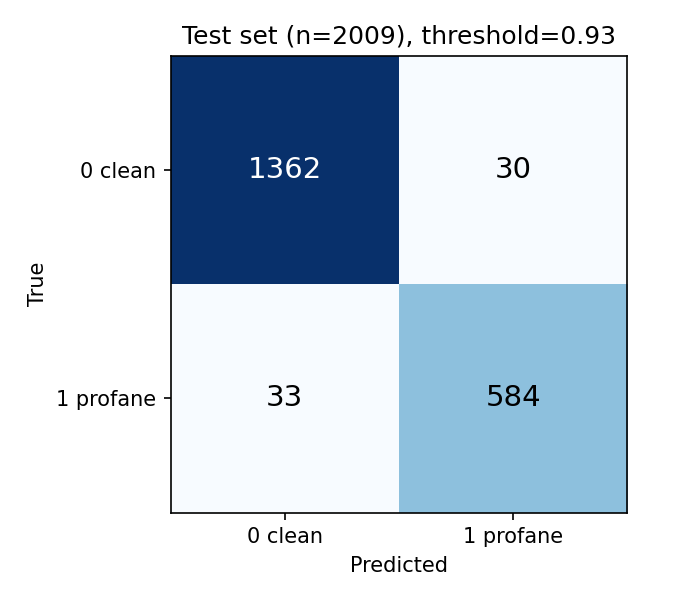

,n,recall
insult_only,215.0,0.9349
kazakh_obscene,193.0,0.9637
masked,9.0,0.7778
mixed_obscene,60.0,0.9667
other,9.0,0.8889
russian_obscene,131.0,0.9466


,n,recall
cyrillic_no_kazakh_letters,178.0,0.9382
cyrillic_with_kazakh_letters,424.0,0.9481
latin,15.0,1.0000


,n,fp_rate
classmate_clean,193.0,0.0311
insult_word_literal,11.0,0.2727
lookalike,202.0,0.0149
neg_sentiment,484.0,0.0227
random,502.0,0.0139


Word-list baseline on the same test set: {'precision': 0.9966, 'recall': 0.9514, 'f1': 0.9735}
95% bootstrap confidence intervals: {'precision': [0.934, 0.9671], 'recall': [0.9261, 0.963], 'f1': [0.9351, 0.9607]}
Calibration (ECE, temperature): {'temperature': 2.0, 'ECE_before_temperature': 0.0329, 'ECE_after_temperature': 0.0138}
Abstention (unsure reviews -> human): {'coverage': 0.9886, 'sent_to_human': 23, 'precision_auto': 0.9511, 'recall_auto': 0.9558, 'f1_auto': 0.9535}

Robustness: the same test reviews rewritten (masked / symbols / Latin / no Kazakh letters)


,n,n_profane,model_f1_original,model_f1_changed,lexicon_f1_changed,example
mask,1698,338,0.938,0.4919,0.9406,сіг*лгір оиын
symbols,1661,315,0.9352,0.8164,0.7143,сігілг1р оиын
latin,1972,604,0.9477,0.9156,0.9443,sigilgir oiyn
no_kazakh,1554,425,0.9516,0.9183,0.9598,Сигилгир оиын


In [10]:
!python src/evaluate.py
from IPython.display import Image, display
display(Image("results/confusion_matrix.png"))
m = json.load(open("results/test_metrics.json"))
display(pd.DataFrame(m["recall_by_profanity_type"]).T)
display(pd.DataFrame(m["recall_by_script"]).T)
display(pd.DataFrame(m["false_positive_rate_by_source"]).T)
print("Word-list baseline on the same test set:", m["lexicon_baseline"])
print("95% bootstrap confidence intervals:", m["bootstrap_95ci"])
print("Calibration (ECE, temperature):", m["calibration"])
print("Abstention (unsure reviews -> human):", m["abstention_0.2_0.8"])
print("\nRobustness: the same test reviews rewritten (masked / symbols / Latin / no Kazakh letters)")
display(pd.DataFrame(json.load(open("results/robustness.json"))).T)

In [11]:
fp = pd.read_csv("results/errors_false_positives.csv", keep_default_na=False)
fn = pd.read_csv("results/errors_false_negatives.csv", keep_default_na=False)
print("False positives (clean, but predicted profane):", len(fp))
display(fp[["text", "probability", "source"]].head(10))
print("False negatives (profane, but missed):", len(fn))
display(fn[["text", "probability", "profanity_type"]].head(10))

False positives (clean, but predicted profane): 30


,text,probability,source
0,Зайбпл екен,0.9720,neg_sentiment
1,Пипес ойын нау,0.9707,classmate_clean
2,Жаман тотакбас,0.9705,neg_sentiment
3,Қплай қолданылатыны түсініксіз,0.9704,random
4,Котек отырык,0.9703,neg_sentiment
5,Ужас ужас тупизм тупизм,0.9700,neg_sentiment
6,Пидезко бул оиын корши баламен оинаимын жжанннн досммен,0.9688,neg_sentiment
7,Задал бала,0.9685,neg_sentiment
8,"Вообще ұнамады ұзақ ойланады ма бірдеме,сосын мал іздесең регионды таңдай алмайсың барлық облыс шығып кетеді,короче ...",0.9679,neg_sentiment
9,"Тауар жынды, өте мықты. Жылдам әрі тез жеткізді. Рахмет.",0.9678,insult_word_literal


False negatives (profane, but missed): 33


,text,probability,profanity_type
0,Сыкты ойн,0.0191,kazakh_obscene
1,"Урод новый версиясы. Мой банкті таппай , перевод жасайын десең. Таппайсың.",0.0199,insult_only
2,"Таңғажайып пернетақта. Мүмкін болса, күш қуаттарың жетсе, Қайсарларың жетсе, батыл болсаңдар, ЛАТИННИЦАНЫ ""нахуй"" ал...",0.0243,russian_obscene
3,Мнаумен моьаж істесен монтаждын басы деген сігіспей қаладыго,0.0250,kazakh_obscene
4,"Зачем безинтернет не входит, маған минутты гб аустру керек бірақ кірмейт тым созып тұра береді без мб кретин қлсаңздар",0.0264,insult_only
5,"После последнего обновления МАЛ болды. Өлік болды, кіре алмайсың. Цифрлық мемлекеттіңді қоя сал",0.0281,insult_only
6,Менин результатым 4август шыккан но али ДАМУМЕДТЕ ЖОК!ПРОГРАММА КОРСЕТПЕЙ ТУР АЛИ!ТУПОЙ ПРОГРАММА,0.0294,insult_only
7,Бұл ойынды қызық ғой точка доступа қосасың достарынмен бірге ойнайсың фай ваймен ойнайсың бірақ қөтіңді қысбаңдар аб...,0.0326,kazakh_obscene
8,***** **** **** бундай приложениянды 667 !!!,0.0328,kazakh_obscene
9,Яптыбаймайт жазылмацды гой😈👿👹👹👹👺👺👹👹👺👻☠💀👽👾,0.0346,other


## 5. Try your own comments

In [12]:
from predict import ProfanityDetector, show
det = ProfanityDetector("model/xlmr-kaz-profanity")
show(det.predict([
    "Тауар сапалы екен, жылдам жеткізді, рахмет!",
    "Өте нашар қызмет, ақшамды қайтарыңдар",
    "Мына қотақбастар ойынды бұзып тастады",
    "Qotaqbas oyin eken",
    "Мал екенсіңдер, ақшамды қайтарыңдар",
    "Мал базары жақсы, таза екен",
]))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[0] p(profane)=0.014  no Kazakh profanity  | Тауар сапалы екен, жылдам жеткізді, рахмет!
[0] p(profane)=0.017  no Kazakh profanity  | Өте нашар қызмет, ақшамды қайтарыңдар
[1] p(profane)=0.975  Kazakh profanity     | Мына қотақбастар ойынды бұзып тастады
[1] p(profane)=0.972  Kazakh profanity     | Qotaqbas oyin eken
[1] p(profane)=0.971  Kazakh profanity     | Мал екенсіңдер, ақшамды қайтарыңдар
[1] p(profane)=0.967  Kazakh profanity     | Мал базары жақсы, таза екен


In [13]:
text = input("Enter a Kazakh comment: ")
show(det.predict(text))

Enter a Kazakh comment: шешеңді сіктім
[1] p(profane)=0.972  Kazakh profanity     | шешеңді сіктім


### Trace one comment from raw text to prediction (useful for the defense)

In [14]:
import torch
from utils import clean_text
text = "Мына qotaqbastar oyindy buzdy"
clean = clean_text(text, det.cfg["normalize"])                     # 1. whitespace + normalization
tokens = det.tokenizer.tokenize(clean)                             # 2. sub-word pieces
enc = det.tokenizer(clean, return_tensors="pt").to(det.device)     # 3. ids + attention mask (+ <s>, </s>)
print("normalized:", clean)
print("tokens:", tokens)
print("input_ids:", enc["input_ids"][0].tolist())
with torch.no_grad():
    logits = det.model(**enc).logits                               # 4. model -> 2 logits
probs = torch.softmax(logits, dim=-1)[0]                           # 5. softmax -> probabilities
thr = det.cfg["threshold"]
print("logits:", logits[0].tolist())
print(f"p(clean)={probs[0]:.4f}  p(profane)={probs[1]:.4f}  threshold={thr}")
print("prediction:", int(probs[1] >= thr))                         # 6. compare with threshold

normalized: Мына қотақбастар ойинды бузды
tokens: ['▁Мына', '▁қо', 'т', 'ақ', 'ба', 'стар', '▁ой', 'и', 'нды', '▁буз', 'ды']
input_ids: [0, 131691, 56697, 222, 7439, 1996, 14669, 17033, 89, 29101, 111223, 1085, 2]
logits: [-3.814894437789917, 3.5134973526000977]
p(clean)=0.0007  p(profane)=0.9993  threshold=0.93
prediction: 1


## 6. Save the model and results
The model folder (~560 MB) is too big for GitHub, so we put it on Google Drive.
After this cell: open Google Drive → `xlmr-kaz-profanity.zip` → Share → **Anyone with the link** → copy the link
and paste it into the README (section "Model download").

In [15]:
from google.colab import drive, files
drive.mount("/content/drive")
!cd model && zip -r -q /content/drive/MyDrive/xlmr-kaz-profanity.zip xlmr-kaz-profanity
!ls -lh /content/drive/MyDrive/xlmr-kaz-profanity.zip
!zip -r -q results.zip results
files.download("results.zip")   # commit these result files to GitHub

Mounted at /content/drive
-rw------- 1 root root 489M Nov 20 15:16 /content/drive/MyDrive/xlmr-kaz-profanity.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Use the trained model without retraining (fresh runtime)
Run section 1 first (clone + install), then this cell. Put the Google Drive file ID
(the long code in the share link `https://drive.google.com/file/d/<FILE_ID>/view`) below.

In [16]:
FILE_ID = "PASTE_FILE_ID_HERE"
!gdown $FILE_ID -O model.zip
!unzip -q -o model.zip -d model
import sys; sys.path.insert(0, "src")
from predict import ProfanityDetector, show
det = ProfanityDetector("model/xlmr-kaz-profanity")
show(det.predict(input("Enter a Kazakh comment: ")))

Failed to retrieve file url:

	Cannot retrieve the public link of the file. You may need to change
	the permission to 'Anyone with the link', or have had many accesses.
	Check FAQ in https://github.com/wkentaro/gdown?tab=readme-ov-file#faq.

You may still be able to access the file from the browser:

	https://drive.google.com/uc?id=PASTE_FILE_ID_HERE

but Gdown can't. Please check connections and permissions.
unzip:  cannot find or open model.zip, model.zip.zip or model.zip.ZIP.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Enter a Kazakh comment: шешеңді сіктім
[1] p(profane)=0.972  Kazakh profanity     | шешеңді сіктім
